<a href="https://colab.research.google.com/github/arxsyy/MachineLearning_2026/blob/main/JS07_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [2]:
df = pd.read_csv('CC_Customer_Dataset.csv')
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [4]:
print(df.shape)
print(df.isna().sum()) # cek missing value
df.describe()

(660, 7)
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
count,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000
mean,330.500000,55141.443939,34574.242424,4.706061,2.403030,2.606061,3.583333
std,190.669872,25627.772200,37625.487804,2.167835,1.631813,2.935724,2.865317
min,1.000000,11265.000000,3000.000000,1.000000,0.000000,0.000000,0.000000
25%,165.750000,33825.250000,10000.000000,3.000000,1.000000,1.000000,1.000000
50%,330.500000,53874.500000,18000.000000,5.000000,2.000000,2.000000,3.000000
75%,495.250000,77202.500000,48000.000000,6.000000,4.000000,4.000000,5.000000
max,660.000000,99843.000000,200000.000000,10.000000,5.000000,15.000000,10.000000


**Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu Avg_Credit_Limit dan Total_credit_card. Apakah sebaran data dapat dikatakan linier?**

Nomor 1: Scatterplot & linieritas

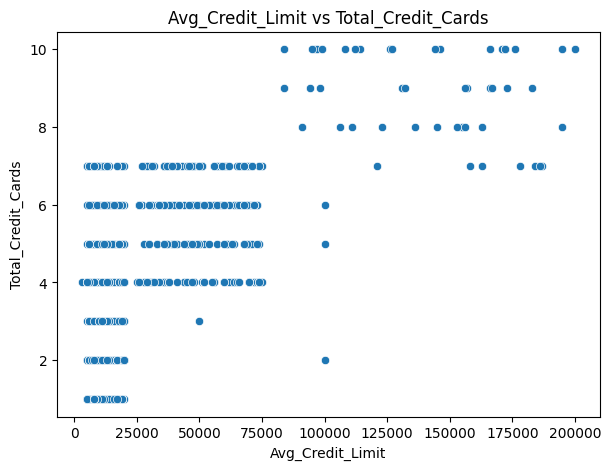

In [5]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='Avg_Credit_Limit', y='Total_Credit_Cards')
plt.title('Avg_Credit_Limit vs Total_Credit_Cards')
plt.show()

Hitung korelasi (pendukung analisis)

In [6]:
print(df['Avg_Credit_Limit'].corr(df['Total_Credit_Cards']))

0.6088604935524963


Apakah sebaran data dapat dikatakan linier?

Sebaran data tidak linier murni (tidak membentuk satu garis lurus), melainkan membentuk pola kelompok/klaster bertingkat. Namun, datanya tetap memiliki tren hubungan positif yang cukup kuat (korelasi 0.61), artinya semakin tinggi limit kredit (Avg_Credit_Limit), jumlah kartu kredit (Total_Credit_Cards) yang dimiliki juga cenderung semakin banyak.

**2. Buatlah model klasterisasi dengan menggunakan model K-Means. Tentukan jumlah k yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.**

In [8]:
# Pilih 2 variabel yang sama seperti nomor 1
X2 = df[['Avg_Credit_Limit', 'Total_Credit_Cards']]

# Scaling (standarisasi) agar kedua variabel punya bobot setara.
scaler2 = StandardScaler()
X2_scaled = scaler2.fit_transform(X2)

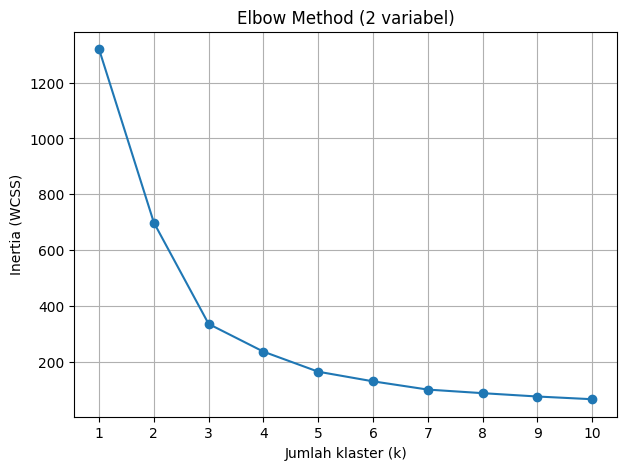

In [9]:
# Elbow method: coba k = 1 sampai 10, simpan inertia masing-masing
# Inertia = total jarak kuadrat titik ke centroid klasternya (makin kecil makin rapat)
inertia = []
K_range = range(1, 11)

for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X2_scaled)
    inertia.append(km.inertia_)

# Linechart elbow
plt.figure(figsize=(7, 5))
plt.plot(K_range, inertia, marker='o')
plt.xlabel('Jumlah klaster (k)')
plt.ylabel('Inertia (WCSS)')
plt.title('Elbow Method (2 variabel)')
plt.xticks(K_range)
plt.grid(True)
plt.show()

**3. Gambarkan hasil klasterisasi dengan model K-Means dengan menggunakan scatterplot.**

Cluster_KMeans
0    330
2    282
1     48
Name: count, dtype: int64


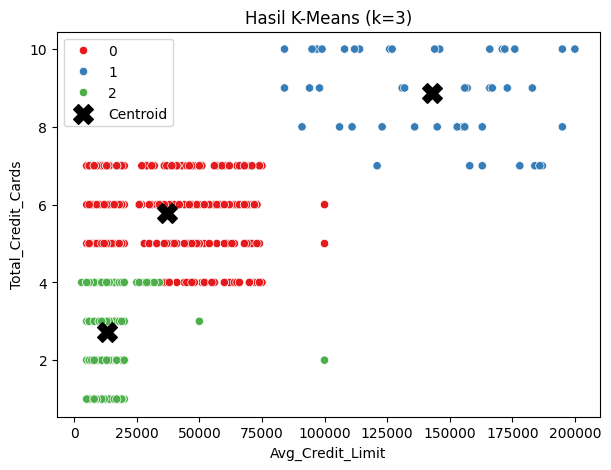

In [10]:
# Latih K-Means dengan k terbaik hasil elbow
k_best = 3   # ganti kalau hasil elbow-mu berbeda
kmeans = KMeans(n_clusters=k_best, n_init=10, random_state=42)

# Simpan label klaster tiap nasabah sebagai kolom baru
df['Cluster_KMeans'] = kmeans.fit_predict(X2_scaled)

# Jumlah anggota tiap klaster
print(df['Cluster_KMeans'].value_counts())

# Scatterplot, warna = klaster
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='Avg_Credit_Limit', y='Total_Credit_Cards',
                hue='Cluster_KMeans', palette='Set1')

# Centroid dikembalikan ke skala asli supaya posisinya cocok dengan sumbu grafik
centroids = scaler2.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centroids[:, 0], centroids[:, 1], c='black', marker='X', s=200, label='Centroid')

plt.title(f'Hasil K-Means (k={k_best})')
plt.legend()
plt.show()

**4. Buatlah model klasterisasi dengan menggunakan DBSCAN dengan seluruh variabel yang dapat digunakan.**

In [11]:
# Sl_No dan Customer Key dibuang karena hanya ID/nomor urut, bukan karakteristik nasabah.
features = ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank',
            'Total_visits_online', 'Total_calls_made']

X_all = df[features]

# DBSCAN berbasis jarak, jadi scaling tetap wajib
X_all_scaled = StandardScaler().fit_transform(X_all)

# Coba beberapa nilai eps untuk melihat pengaruhnya
# eps = radius tetangga, min_samples = minimal titik agar dianggap padat
for eps in [0.5, 0.8, 1.0, 1.2, 1.5]:
    lbl = DBSCAN(eps=eps, min_samples=5).fit_predict(X_all_scaled)
    n_clust = len(set(lbl)) - (1 if -1 in lbl else 0)   # label -1 = noise, tidak dihitung klaster
    print(f'eps={eps} -> klaster={n_clust}, noise={(lbl == -1).sum()}')

eps=0.5 -> klaster=24, noise=205
eps=0.8 -> klaster=2, noise=44
eps=1.0 -> klaster=2, noise=18
eps=1.2 -> klaster=2, noise=4
eps=1.5 -> klaster=2, noise=1


In [12]:
# Model DBSCAN final (ganti eps/min_samples sesuai pilihanmu dari sel 8)
dbscan = DBSCAN(eps=1.0, min_samples=5)
df['Cluster_DBSCAN'] = dbscan.fit_predict(X_all_scaled)

# Label -1 artinya noise (titik yang tidak masuk klaster mana pun)
print(df['Cluster_DBSCAN'].value_counts())

Cluster_DBSCAN
 0    608
 1     34
-1     18
Name: count, dtype: int64


**5. Tentukan jumlah k yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.**

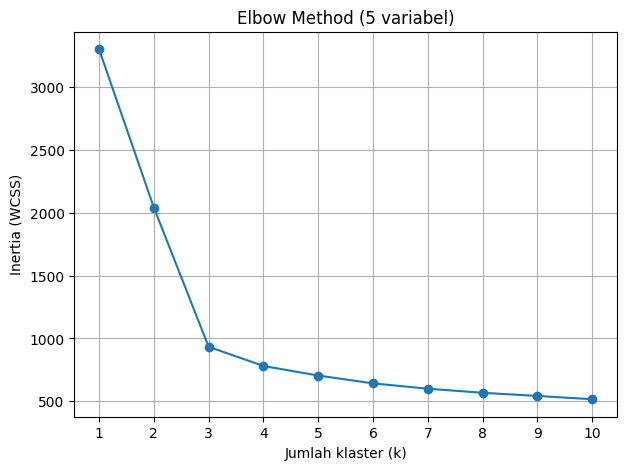

In [13]:
# Elbow method untuk seluruh variabel (pakai K-Means, karena DBSCAN tidak punya parameter k)
inertia_all = []

for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_all_scaled)
    inertia_all.append(km.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), inertia_all, marker='o')
plt.xlabel('Jumlah klaster (k)')
plt.ylabel('Inertia (WCSS)')
plt.title('Elbow Method (5 variabel)')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

Berdasarkan grafik linechart Elbow Method pada 5 variabel, jumlah klaster terbaik yang dipilih adalah k=3. Nilai ini dipilih karena pada titik k=1 hingga k=3 terjadi penurunan nilai inertia (WCSS) yang sangat tajam (dari sekitar 3.300 turun drastis ke -930), sedangkan setelah k=3 garis mulai melandai (membentuk siku/elbow) sehingga penambahan jumlah klaster berikutnya tidak lagi memberikan penurunan error yang signifikan.

**6. Tentukan nilai silhouette score dan DBI dari model DBSCAN.**

In [14]:
# Evaluasi DBSCAN
labels = df['Cluster_DBSCAN']

# Buang noise (-1) dulu, karena silhouette & DBI butuh minimal 2 klaster
# dan noise bukan klaster sebenarnya
mask = labels != -1
X_clean = X_all_scaled[mask]
labels_clean = labels[mask]

sil = silhouette_score(X_clean, labels_clean)
dbi = davies_bouldin_score(X_clean, labels_clean)

print(f'Silhouette Score : {sil:.4f}')
print(f'Davies-Bouldin   : {dbi:.4f}')

Silhouette Score : 0.5680
Davies-Bouldin   : 0.6015
